# Overlays and the allowance roll-forward

**Question:** Does the allowance roll-forward of a bank close from the opening to the closing balance, which movement explains each change, and how large are the management overlays that sit on top of the model ECL?

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 to 03 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- read the IFRS 7 roll-forward of the allowance and of the gross carrying amount by stage, and say which identities must close;
- rebuild the roll-forward rows with the engine from a committed waterfall and judge them with `check_identities`, stating the tolerance basis exactly;
- plant a defect in a movement and see which identity names it, and see that a defect below the tolerance passes;
- report management overlays as separate, attributed lines that never enter the model ECL, and compute the total allowance and the overlay diagnostics;
- explain what an overlay that does not move with the scenario tells a validator.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))
LIGHT = {"green": "green", "amber": "amber", "red": "red"}
SCENARIO = {"base": "base", "recession": "recession"}

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two cases are read, from three committed files.

- **C06** at 2008-12-31 (`data/derived/C06/rd-2008-12.json`): SBA 7(a) loans, U.S. Government Works, licence class `mirror-allowed`. The roll-forward of the allowance and of the gross carrying amount by stage (`outputs.reconciliation`), the waterfall of the allowance (`outputs.waterfall`), the stage totals (`outputs.stage_summary`) and the list of overlays (`outputs.overlays`), which is empty for this date.
- **C07** (`data/derived/C07/base.json` and `data/derived/C07/recession.json`): Banco Andino, a **synthetic** bank generated and calibrated to public aggregates of the CMF, Chile's supervisor. It is not a real bank and not evidence about any bank. Its IFRS 9 view has two overlays (`outputs.ifrs9_detail.overlays`), each a separate line, whose amounts are assumptions of the case (a share of the base ECL of a segment). Amounts are in Chilean pesos (CLP).

The next cell loads the three files and prints the engine versions that baked them.

In [2]:
# Load the C06 reporting date and the two C07 scenarios
from riskvalidation.provisions import ecl as ecl_engine, overlays as ovl, reconciliation as rec
from riskvalidation.validation import ifrs9

ROOT = Path("../../..").resolve()
DERIVED = ROOT / "data" / "derived"
c06 = json.loads((DERIVED / "C06" / "rd-2008-12.json").read_text(encoding="utf-8"))
base = json.loads((DERIVED / "C07" / "base.json").read_text(encoding="utf-8"))
recession = json.loads((DERIVED / "C07" / "recession.json").read_text(encoding="utf-8"))
out = c06["outputs"]
baked = [a["provenance"]["riskvalidation_version"] for a in (c06, base, recession)]
print("engine that baked C06, C07 base and C07 recession:", *baked)
print("engine installed now:", md.version("riskvalidation"))
print("C07 is synthetic:", "yes" if base["outputs"]["synthetic"] else "no")

engine that baked C06, C07 base and C07 recession: 1.0.1 1.0.1 1.0.1
engine installed now: 1.0.1
C07 is synthetic: yes


## Method

IFRS 7 35H asks for a reconciliation of the opening to the closing loss allowance by stage, and 35I the same for the gross carrying amount, with the movements that explain the change: originations, transfers between stages, re-measurement, write-offs and derecognition. For each stage row of either table, and with $\mathrm{residual}$ the amount the engine reports:

$$\mathrm{residual} = \mathrm{closing} - \Bigl(\mathrm{opening} + \sum_k \mathrm{movement}_k\Bigr)$$

Contraste's engine adds four identities between the tables and the waterfall: the waterfall closes (opening plus its lines equals its closing), the waterfall closing equals the sum of the stage closings, each waterfall line equals the sum of the stage movements with that line identifier, and the allowance closing of a stage equals its stage ECL plus the overlay carried in that stage. Overlays are separate lines (BCBS d350, paragraphs 50 and 51; ECB 2024) and enter the total allowance only:

$$\mathrm{LA} = \sum_{S1} \mathrm{ECL}_{12m} + \sum_{S2} \mathrm{ECL}_{\mathrm{life}} + \sum_{S3} \mathrm{ECL}_{D} + \sum_{\mathrm{POCI}} \Delta\mathrm{ECL} + \sum_k \mathrm{OVL}_k$$

**The tolerance basis**, read in the engine's source at its release (`provisions/reconciliation.py`): a money identity closes when its absolute difference is at most $\mathrm{tolerance} \times \max(1, G)$, with $G$ the sum of the absolute closing amounts of the gross carrying amount rows. The default tolerance is $10^{-6}$, so the allowed difference is one millionth of the book, not one millionth of a unit of money. It is Contraste's internal gate, not a regulatory threshold.

The overlay diagnostics (ECB 2024) are the share of the overlay in the total allowance, the split by stage, segment and target (parameter level or total level), and whether a positive overlay stands in an improving scenario. The stage rule for where an overlay is carried (an overlay with no stage goes to Stage 1) is a convention of the engine's contract, not an IFRS rule.

### Step 1: rebuild the roll-forward rows with the engine

`allowance_rollforward` and `gca_rollforward` build one row per stage from an opening, a dictionary of movements and a closing, and report the residual. We feed them the committed numbers of C06 (the three stages of each table) and print the opening, the closing and the residual of each row. The cell then offers a movement that IFRS 7 35I does not list, a `coupon`, to see the engine refuse it and count the identifiers it does accept.

In [3]:
# Rebuild the stage rows of both roll-forwards with the engine
recon = out["reconciliation"]
allow_moves = [{m["line_id"]: m["amount"] for m in r["movements"]} for r in recon["allowance"]]
gca_moves = [{m["line_id"]: m["amount"] for m in r["movements"]} for r in recon["gross_carrying_amount"]]
allowance = [rec.allowance_rollforward(r["stage"], r["opening"], mv, r["closing"])
             for r, mv in zip(recon["allowance"], allow_moves)]
gca = [rec.gca_rollforward(r["stage"], r["opening"], mv, r["closing"])
       for r, mv in zip(recon["gross_carrying_amount"], gca_moves)]
for table, rows in (("35H", allowance), ("35I", gca)):
    for row in rows:
        print(table, "Stage", row.stage[-1], "| opening, millions:", round(row.opening / 1e6, 3),
              "| closing, millions:", round(row.closing / 1e6, 3), "| residual:", f"{row.residual:.0e}")
try:
    rec.gca_rollforward("stage1", 1.0, {"coupon": 1.0}, 2.0)
except ValueError:
    print("a movement the standard does not list is refused; identifiers the engine accepts:")
    print(len(rec.GCA_LINE_IDS))

35H Stage 1 | opening, millions: 433.354 | closing, millions: 798.078 | residual: 0e+00
35H Stage 2 | opening, millions: 0.246 | closing, millions: 68.929 | residual: -1e-08
35H Stage 3 | opening, millions: 0.0 | closing, millions: 0.0 | residual: 0e+00
35I Stage 1 | opening, millions: 47338.013 | closing, millions: 46716.271 | residual: 0e+00
35I Stage 2 | opening, millions: 7.734 | closing, millions: 531.345 | residual: -1e-07
35I Stage 3 | opening, millions: 0.0 | closing, millions: 0.0 | residual: 0e+00
a movement the standard does not list is refused; identifiers the engine accepts:
9


All six rows close: the residuals are zero or at most 1e-07 USD, rounding noise on balances of hundreds of millions. In Stage 1 the allowance goes from 433.354 to 798.078 million USD and in Stage 2 from 0.246 to 68.929 million, while the gross carrying amount of Stage 1 goes from 47,338.013 to 46,716.271 million. The refusal of the `coupon` movement is part of the contract: a movement that the standard does not list cannot enter the table, so the table cannot be balanced by an invented line.

### Step 2: the waterfall of the whole allowance

The waterfall is the account of the whole allowance: the opening, each movement and the closing, in one column of lines. The stage tables of step 1 are its breakdown. The cell draws it from the committed lines, with increases in green, decreases in red and the opening and closing in blue. Read it from left to right, each bar starting where the previous one ended.

Opening allowance               433.600
Originations                     99.569
Transfer 1 to 2                  51.873
Transfer 2 to 3                 926.449
Transfer 2 to 1                   0.000
Remeasurement                   391.917
Macro update                     -9.308
Write-off                      -967.317
Derecognition (repaid or matured)    -59.777
Closing allowance               867.007


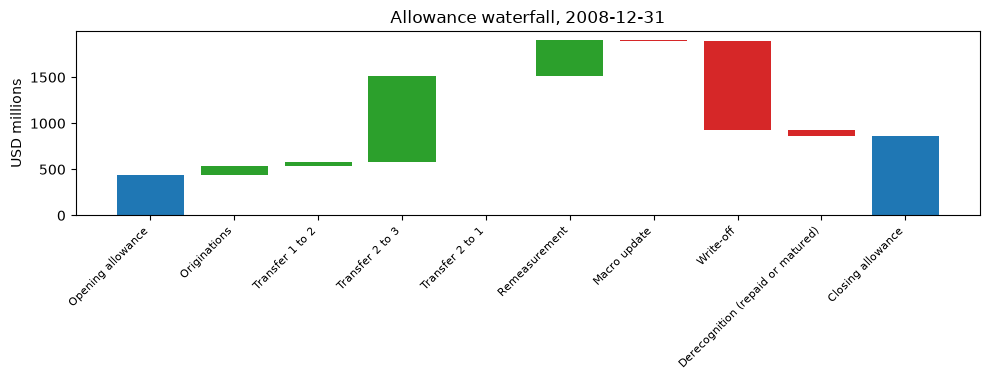

In [4]:
# Draw the waterfall of the allowance: the opening, each movement and the closing
lines = out["waterfall"]["lines"]
fig, ax = plt.subplots(figsize=(10, 3.9))
running = 0.0
for i, line in enumerate(lines):
    amount = line["amount"] / 1e6
    if line["kind"] in ("opening", "closing"):
        ax.bar(i, amount, color="tab:blue")
        running = amount
    else:
        ax.bar(i, abs(amount), bottom=running if amount >= 0 else running + amount,
               color="tab:green" if amount >= 0 else "tab:red")
        running += amount
labels = [line["label"]["en"] for line in lines]
for label, line in zip(labels, lines):
    print(f"{label:28s} {line['amount'] / 1e6:10.3f}")
ax.set_xticks(range(len(lines)))
ax.set_xticklabels(labels, rotation=45, ha="right", fontsize=8)
ax.set_ylabel("USD millions")
ax.set_title("Allowance waterfall, 2008-12-31")
fig.tight_layout()
plt.show()

The allowance opens at 433.600 million USD and closes at 867.007 million, the weighted allowance of notebook 03. The largest bars are the transfer from Stage 2 to Stage 3, 926.449 million, and the write-off, 967.317 million: the loans that default are charged off inside the year, so almost the same amount enters Stage 3 and leaves it, and no Stage 3 allowance remains at the date (finding `F-NO-DELINQUENCY`). The re-measurement of 391.917 million is the other large increase, and the macro update, 9.308 million, is a small decrease.

### Step 3: the identities and their tolerance

`identity_residuals` returns the absolute residual of every identity by name and `check_identities` the names of those that fail. They need the rows of step 1, the waterfall lines of step 2 and the stage ECL, which is the committed stage summary. The cell prints how many identities there are, the largest residual, the tolerance basis (one millionth of the gross carrying amount $G$ of the book) and the light of the engine's own `reconciliation_identities` test.

In [5]:
# Judge the identities, print the tolerance basis and run the engine's own test
stage_ecl = {r["stage"]: r["ecl"] for r in out["stage_summary"]["rows"]}
residuals = rec.identity_residuals(allowance, gca, lines, stage_ecl)
G = rec.gross_total(gca)
test = ifrs9.reconciliation_identities(allowance, gca, lines, stage_ecl, model_id="c06")
print("identities:", len(residuals), "| largest residual, USD:", f"{max(residuals.values()):.1e}")
print("G, millions:", round(G / 1e6, 1))
print("absolute limit 1e-6 x G, USD:", round(1e-6 * max(1.0, G), 1))
print("identities that fail:", rec.check_identities(allowance, gca, lines, stage_ecl))
print("engine test, largest residual:", f"{test.metric:.0e}", "| light:", LIGHT[test.light.value])
print("tolerance, USD:", round(test.extras["tolerance"], 1))

identities: 12 | largest residual, USD: 1.2e-07
G, millions: 47247.6
absolute limit 1e-6 x G, USD: 47247.6
identities that fail: []
engine test, largest residual: 1e-07 | light: green
tolerance, USD: 47247.6


Twelve identities tie the stage tables to the waterfall and every one closes: the largest residual is 1.2e-07 USD, against an absolute limit of 47,247.6 USD, and the engine's own test is green. The tolerance deserves a sentence next to the result because it is relative to the book: one millionth of $G$, which is 47,247.6 million USD, is 47,247.6 USD, not one millionth of a dollar. A gate with that basis protects against an error of the size of a movement, which the next step measures.

### Step 4: plant a defect and see who names it

A gate is only worth what it catches. The cell copies the Stage 1 allowance row and adds to its re-measurement a defect that the closing does not carry, from 1 USD to 100 million USD in 81 steps, and asks `check_identities` at each size whether anything fails. It does so at the default tolerance of $10^{-6}$ and at a tight one of $10^{-9}$. The figure plots detected or not against the size, with the limit of each tolerance.

tolerance 1e-06 | limit, USD: 47247.6
   smallest defect caught, USD: 50118.7
tolerance 1e-09 | limit, USD: 47.2
   smallest defect caught, USD: 50.1


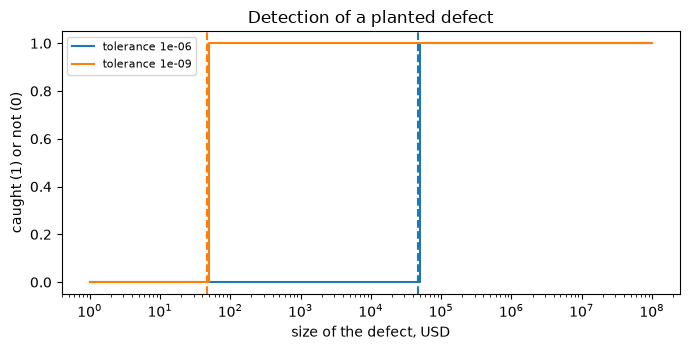

In [6]:
# Plant a defect of growing size in the Stage 1 row and ask from which size the gate names it
first = recon["allowance"][0]
sizes = np.logspace(0, 8, 81)
planted = [
    rec.allowance_rollforward(first["stage"], first["opening"],
                              {**allow_moves[0], "remeasurement": allow_moves[0]["remeasurement"] + size},
                              first["closing"])
    for size in sizes
]
caught = {}
fig, ax = plt.subplots(figsize=(7, 3.6))
for tolerance, color in ((1e-6, "tab:blue"), (1e-9, "tab:orange")):
    flags = [rec.check_identities([row] + allowance[1:], gca, lines, stage_ecl, tolerance=tolerance) for row in planted]
    caught[tolerance] = [bool(f) for f in flags]
    smallest = float(sizes[caught[tolerance].index(True)])
    print("tolerance", tolerance, "| limit, USD:", round(tolerance * G, 1))
    print("   smallest defect caught, USD:", round(smallest, 1))
    detected = np.array(caught[tolerance], dtype=float)
    ax.step(sizes, detected, where="post", color=color, label=f"tolerance {tolerance}")
    ax.axvline(tolerance * G, color=color, linestyle="--")
ax.set_xscale("log")
ax.set_xlabel("size of the defect, USD")
ax.set_ylabel("caught (1) or not (0)")
ax.set_title("Detection of a planted defect")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The gate names the defect from the size of its limit and not before: at the default tolerance nothing below 47,247.6 USD is caught, and the first size on the grid that is caught is 50,118.7 USD, the first grid point above the limit. Tightening the tolerance to $10^{-9}$ moves the limit to 47.2 USD and the first size caught to 50.1 USD. The dashed lines mark the limits and the steps rise right after them: the tolerance is the detection threshold, and a validator who reports a green gate should report it with this number.

### Step 5: overlays as separate lines

C06 has no overlay at this date. C07's IFRS 9 view has two, committed as lines with an identifier, a segment, a stage and an amount. The engine's `Overlay` asks for more: a method, a target, a staging effect and a review date. The cell builds them from the committed lines, with the target read from the committed diagnostic row and a review date that is a lesson input. It then asks `overlay_lines` for the lines, `total_allowance` for the total over the model ECL and `overlay_diagnostics` for the share.

In [7]:
# Build the engine's overlays from the committed lines and compute the total allowance and the diagnostics
detail = base["outputs"]["ifrs9_detail"]
row = [t for t in base["tests"] if t["test_id"] == "ifrs9.overlay_diagnostics"][0]
by_target = {amount: target for target, amount in row["extras"]["by_target"].items() if amount}
REVIEW_DATE = "2026-08-31"  # lesson input: the artifact does not hold the review date
overlays = [
    ovl.Overlay(id=o["id"], rationale_en=o["label"]["en"], rationale_es=o["label"]["es"], method="expert",
                target=by_target[o["amount"]], segment_id=o["segment_id"], stage=o["stage"], amount=o["amount"],
                staging_effect="none", review_date=REVIEW_DATE, currency="CLP")
    for o in detail["overlays"]
]
for line in ovl.overlay_lines(overlays):
    print(line["id"], "| Stage", line["stage"][-1], "| amount, CLP millions:", round(line["amount"] / 1e6, 3))
stage_model = {r["stage"]: r["ecl"] for r in detail["stage_summary"] if r["stage"] != "poci"}
model_total = sum(stage_model.values())
total = ovl.total_allowance(model_total, overlays)
print("model ECL, CLP millions:", round(model_total / 1e6, 1))
print("total allowance, CLP millions:", round(total / 1e6, 1))
carried = rec.carried_by_stage(overlays)
print("carried in Stage 1 and Stage 2, millions:")
print(round(carried["stage1"] / 1e6, 1), round(carried["stage2"] / 1e6, 1))
diag = ifrs9.overlay_diagnostics(overlays, stage_model, 0, model_id="c07")
print("overlay share of the allowance:", round(diag.metric, 6), "| light:", LIGHT[diag.light.value])

overlay-OVL-CARDS | Stage 1 | amount, CLP millions: 226.934
overlay-OVL-HOUSING | Stage 2 | amount, CLP millions: 97.196
model ECL, CLP millions: 97267.9
total allowance, CLP millions: 97592.0
carried in Stage 1 and Stage 2, millions:
226.9 97.2
overlay share of the allowance: 0.003321 | light: green


Banco Andino's two overlays are 226.934 million CLP on cards, carried in Stage 1, and 97.196 million on high-LTV mortgages, carried in Stage 2. They are lines of their own, each with its rationale, method and target, and they never enter the model ECL: the model ECL is 97,267.9 million CLP and the total allowance is 97,592.0 million, the sum. The overlay share of the allowance is 0.003321, 0.33%, which the diagnostic reads as green. Kept apart, the overlays can be audited one by one, which a single adjusted ECL figure would not allow.

### Step 6: what makes the diagnostics change colour

The light of `overlay_diagnostics` reads the share of the overlay in the allowance (amber above 10%, red above 25%) and the direction: a positive overlay in a scenario that improved is inconsistent. The cell multiplies the overlays of step 5 by factors from 0 to 300, which are what-if runs and not Contraste data, and reads the share and the light at each. It also runs the same overlays in an improving scenario to see the direction check act. The figure draws the share against the factor with the two cut-offs.

overlays multiplied by 0 | share: 0.0
    green
overlays multiplied by 1 | share: 0.0033
    green
overlays multiplied by 25 | share: 0.0769
    green
overlays multiplied by 50 | share: 0.1428
    amber
overlays multiplied by 100 | share: 0.2499
    amber
overlays multiplied by 150 | share: 0.3333
    red
overlays multiplied by 200 | share: 0.3999
    red
overlays multiplied by 250 | share: 0.4545
    red
overlays multiplied by 300 | share: 0.4999
    red
improving scenario, positive overlays: light: amber
direction consistent: no


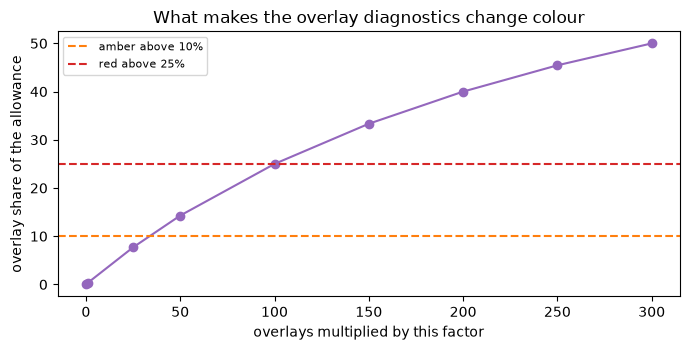

In [8]:
# Scale the overlays and flip the scenario direction to see the share and the direction check
factors = [0, 1, 25, 50, 100, 150, 200, 250, 300]
shares = []
for factor in factors:
    scaled = [dataclasses.replace(o, amount=o.amount * factor) for o in overlays]
    d = ifrs9.overlay_diagnostics(scaled, stage_model, 0)
    shares.append(d.metric)
    print("overlays multiplied by", factor, "| share:", round(d.metric, 4))
    print("   ", LIGHT[d.light.value])
improving = ifrs9.overlay_diagnostics(overlays, stage_model, -1)
print("improving scenario, positive overlays: light:", LIGHT[improving.light.value])
print("direction consistent:", "yes" if improving.extras["direction_consistent"] else "no")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(factors, [100 * s for s in shares], marker="o", color="tab:purple")
ax.axhline(10, color="tab:orange", linestyle="--", label="amber above 10%")
ax.axhline(25, color="tab:red", linestyle="--", label="red above 25%")
ax.set_xlabel("overlays multiplied by this factor")
ax.set_ylabel("overlay share of the allowance")
ax.set_title("What makes the overlay diagnostics change colour")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

At the committed size the overlays are 0.33% of the allowance. Multiplied by 25 they are 7.7%, still green; multiplied by 50 they are 14%, amber; multiplied by 100 they are 24.99%, amber and just under the red cut-off of 25%; from 150 on they are red. In an improving scenario the same positive overlays make the direction check fail and the light turns amber, although the share is small. These runs show how the diagnostic moves, with the share in percent on the vertical axis, and say nothing about Banco Andino's real overlays.

### Step 7: an overlay that does not follow the scenario

The C07 overlays are fixed in the case at 10% and 8% of the **base** ECL of their segment. The recession variant provisions the same bank under a harsher scenario. The cell reads the model ECL and the overlay total of both variants, computes the overlay share of the total allowance and checks whether the overlay amounts are the same in both. The figure draws the model ECL and the overlay share by scenario.

base       | model ECL, CLP millions:    97267.9
           | overlays:  324.1
           | overlay share of the total: 0.00332
recession  | model ECL, CLP millions:   169463.6
           | overlays:  324.1
           | overlay share of the total: 0.00191
overlay amounts identical in both variants: yes


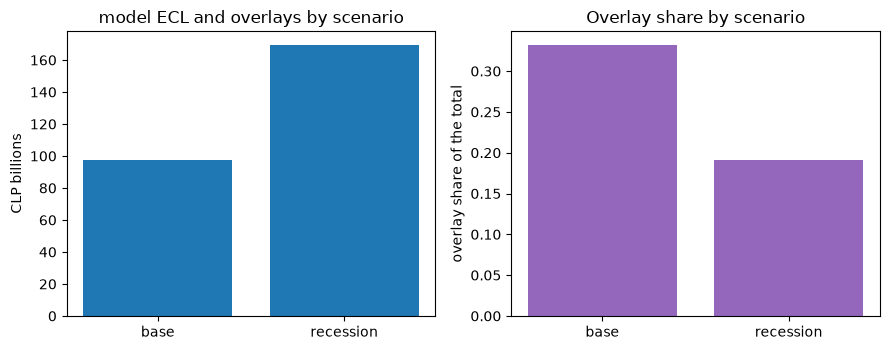

In [9]:
# Compare the model ECL and the overlays of the base and the recession variants of Banco Andino
variants = {"base": base, "recession": recession}
model_ecl, overlay_total, share = {}, {}, {}
for name, art in variants.items():
    d = art["outputs"]["ifrs9_detail"]
    model_ecl[name] = sum(r["ecl"] for r in d["stage_summary"])
    overlay_total[name] = d["overlays_total"]
    share[name] = overlay_total[name] / (model_ecl[name] + overlay_total[name])
    print(f"{SCENARIO[name]:10s} | model ECL, CLP millions: {model_ecl[name] / 1e6:10.1f}")
    print(f"{'':10s} | overlays: {overlay_total[name] / 1e6:6.1f}")
    print(f"{'':10s} | overlay share of the total: {share[name]:.5f}")
amounts = [[o["amount"] for o in a["outputs"]["ifrs9_detail"]["overlays"]] for a in variants.values()]
print("overlay amounts identical in both variants:", "yes" if amounts[0] == amounts[1] else "no")

fig, (left, right) = plt.subplots(1, 2, figsize=(9, 3.6))
names = [SCENARIO[n] for n in variants]
left.bar(names, [model_ecl[n] / 1e9 for n in variants], color="tab:blue")
left.set_ylabel("CLP billions")
left.set_title("model ECL and overlays by scenario")
right.bar(names, [100 * share[n] for n in variants], color="tab:purple")
right.set_ylabel("overlay share of the total")
right.set_title("Overlay share by scenario")
fig.tight_layout()
plt.show()

In the recession variant the model ECL grows from 97,267.9 to 169,463.6 million CLP while the overlays stay at 324.1 million, so their share of the allowance falls from 0.33% to 0.19%. An overlay that is sized once on the base case and does not move when the scenario worsens protects less exactly when the bank needs it. A validator reads that as the signature of an overlay without a method behind it; the ECB (2024) asks that overlays rest on a method such as a simulation or a scenario analysis, which would let them move with the scenario.

## Results

**Answer:** Yes, the roll-forward closes: all 12 identities hold with a largest residual of 1.2e-07 USD against a limit of 47247.6 USD, and the allowance of the 2008 book grows from 433.600 to 867.007 million USD mainly through re-measurement (391.917 million) and originations (99.569 million), with 926.449 million transferred to Stage 3 and 967.317 million written off; Banco Andino's two overlays add 324.1 million CLP, 0.33% of the allowance (0.003321), and stay at 324.1 when the model ECL grows from 97267.9 to 169463.6 million.

- **The roll-forward closes.** The six stage rows (three of the allowance, three of the gross carrying amount) rebuild with the engine and have residuals of at most 1e-07 USD. In Stage 1 the allowance goes from 433.354 to 798.078 million USD and in Stage 2 from 0.246 to 68.929; the gross carrying amount of Stage 1 goes from 47,338.013 to 46,716.271 million. A movement outside the IFRS 7 35I list is refused.
- **Twelve identities hold.** `check_identities` returns an empty list and the engine's own test is green. The waterfall opens at 433.600 million, the sum of the three stage openings, and closes at 867.007, the allowance of notebook 03.
- **The tolerance is relative, and that is a property to state.** $G$ is 47,247.6 million USD, so the default limit is 47,247.6 USD. A defect is first caught on the grid at 50,118.7 USD; with the tolerance tightened to $10^{-9}$, at 50.1 USD. The gate protects the book against an error of the size of a movement, not against a rounding of a few thousand USD.
- **Stage 3 closes at zero by construction of the data.** The transfer from Stage 2 to Stage 3 is 926.449 million and the write-off is 967.317 million: the loans default and are charged off inside the year, and no Stage 3 allowance is left at the date (finding `F-NO-DELINQUENCY`).
- **The overlays are lines, and the total reconciles.** Banco Andino's two overlays are 226.934 million CLP (cards, Stage 1) and 97.196 (high-LTV mortgages, Stage 2). The model ECL is 97,267.9 million, the total allowance 97,592.0, and the overlay share is 0.003321, green.
- **The diagnostics move as the rules say.** The same overlays multiplied by 100 are 24.99% of the allowance, amber and just under the red cut-off of 25%; multiplied by 150 or more they are red. In an improving scenario a positive overlay makes the direction check fail and the light amber. These are what-if runs.
- **An overlay that does not follow the scenario.** In the recession variant the model ECL grows from 97,267.9 to 169,463.6 million CLP and the overlays stay at 324.1, so their share falls from 0.33% to 0.19%. A validator reads this as an overlay sized once on the base case.

What this notebook does not show: the closing of the identities is a statement about the arithmetic consistency of the tables, not about whether the allowance is right, and the engine states no compliance claim. The review date of the overlays is a lesson input, and C07 is a synthetic bank.

## Summary

- The IFRS 7 roll-forward of the allowance and of the gross carrying amount is rebuilt row by row with the engine, and twelve identities tie the stage tables to the waterfall.
- The gate closes within a tolerance of one millionth of the gross carrying amount of the book, so it catches an error of the size of a movement and lets a few thousand USD pass; a validator states the basis next to the result.
- Overlays are separate, attributed lines that enter the total allowance only, never the model ECL or the stage ECL; the engine carries an overlay with no stage in Stage 1 by convention.
- The overlay diagnostics read the share of the allowance, its split and the direction against the scenario; an overlay fixed in the case does not follow a harsher scenario.
- An identity that closes says the tables agree with each other, not that the allowance is adequate.

**What to try next.** Plant a defect in another movement, or in the gross carrying amount table, and read which identities name it; change `REVIEW_DATE` and see that the totals do not move. Then continue with notebook 05, which validates the whole battery on six reporting dates.

## References

- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, July 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm
- EBA (2023), IFRS 9 implementation by EU institutions, 2023 monitoring report, EBA/Rep/2023/36, paragraphs 29 to 33 and 94 to 118. https://www.eba.europa.eu/sites/default/files/2023-11/25b12d35-9c28-4335-a589-166c77198920/Final%20Report%20on%20IFRS9%20implementation%20by%20EU%20institutions.pdf